1) A imagem original da Lena gray possui resolução 512 x 512 pixels. Decime essa imagem para
256 x 256, 128 x 128 e 64 x 64. Exiba as imagens lado a lado e do mesmo tamanho que a imagem
original. Comente.

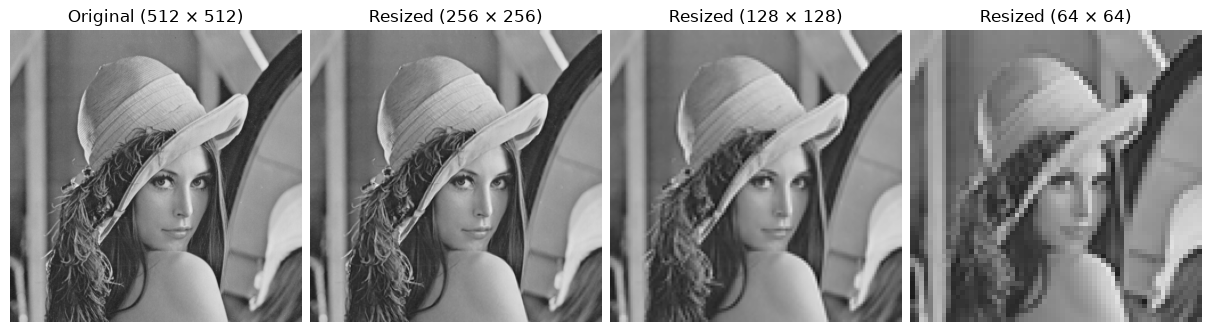

In [9]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image

# Localização do arquivo de imagem
image_url = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")

# Abertura do arquivo de imagem
with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

# Uso da função .resize do Pillow junto a Image.Resampling.LANCZOS para manter o tamanho da imagem exibida
resized_1 = original.resize((256, 256), Image.Resampling.LANCZOS)
resized_2 = original.resize((128, 128), Image.Resampling.LANCZOS)
resized_3 = original.resize((64, 64), Image.Resampling.LANCZOS)

# Organização dos plots em uma linha por 4 colunas
fig, axes = plt.subplots(1, 4, figsize=(12, 4), constrained_layout=True)

# Plots e títulos
axes[0].imshow(original)
axes[0].set_title(f"Original ({original.width} × {original.height})")
axes[1].imshow(resized_1)
axes[1].set_title("Resized (256 × 256)")
axes[2].imshow(resized_2)
axes[2].set_title("Resized (128 × 128)")
axes[3].imshow(resized_3)
axes[3].set_title("Resized (64 × 64)")

for ax in axes:
    ax.axis("off")
    ax.set_box_aspect(1)

plt.show()

COMENTÁRIO 1 - 
Visivelmente, ao reduzir a quantidade de pixels da Lena Gray, a definição é reduzida causando pixelamento visual na imagem. 

2) Exiba os canais da Lena color. Explique por que cada canal é exibido em níveis de cinza embora
representem as componente R, G e B.

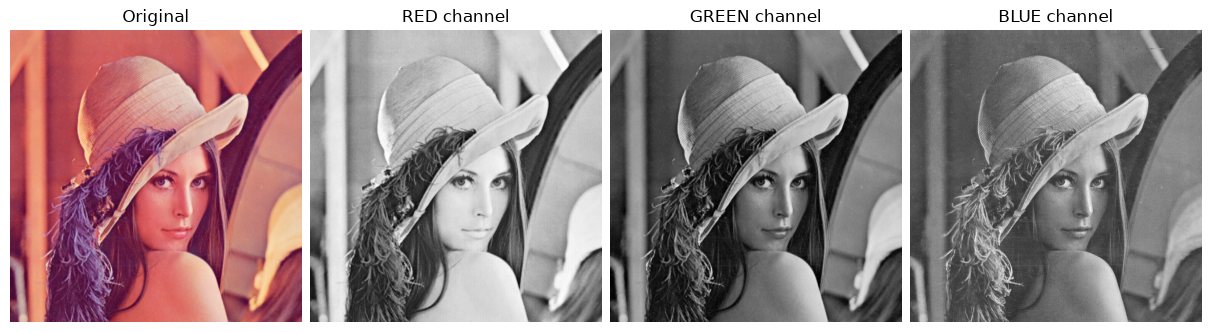

In [10]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image

# Localização do arquivo de imagem
image = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena3.tif")

# Abertura do arquivo de imagem
with urlopen(image) as response:
    image = Image.open(BytesIO(response.read()))

# Uso da função .getchannel para obter os canais da imagem
image_R = image.getchannel("R")
image_G = image.getchannel("G")
image_B = image.getchannel("B")

# Organização dos plots em 1 linha por 4 colunas
fig, axes = plt.subplots(1, 4, figsize=(12, 4), constrained_layout=True)

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(image)
axes[0].set_title("Original") 

axes[1].imshow(image_R, cmap="gray")
axes[1].set_title("RED channel")

axes[2].imshow(image_G, cmap="gray")
axes[2].set_title("GREEN channel")

axes[3].imshow(image_B, cmap="gray")
axes[3 ].set_title("BLUE channel")

for ax in axes:
    ax.axis("off")
    ax.set_box_aspect(1)

plt.show()

COMENTÁRIO 2 - 
Cada canal é exibido em níveis de cinza embora sejam os canais R,G e B pois os canais individuais são transformados em uma matriz 2D por .getchannel e os valores individuais dos pixels são comparados a escala de 0 a 255 de níveis de cinza, não obtendo exatamente os vermelhos, verdes e azuis, mas as intensidades correspondentes.

3) Quantos bits por pixel temos na Lena color e quantos na Lena gray? Quantize a Lena gray com 6,
4, 2 e 1 bit por pixel. Exiba a imagem original e versões quantizadas lado a lado e comente os
resultados.

Image 1: size (512, 512) and  bits: (8, 8, 8).
Image 2: size (512, 512) and  bits: (8,). For this single channel image (grayscale), the number of colors is 2^(num_bits)


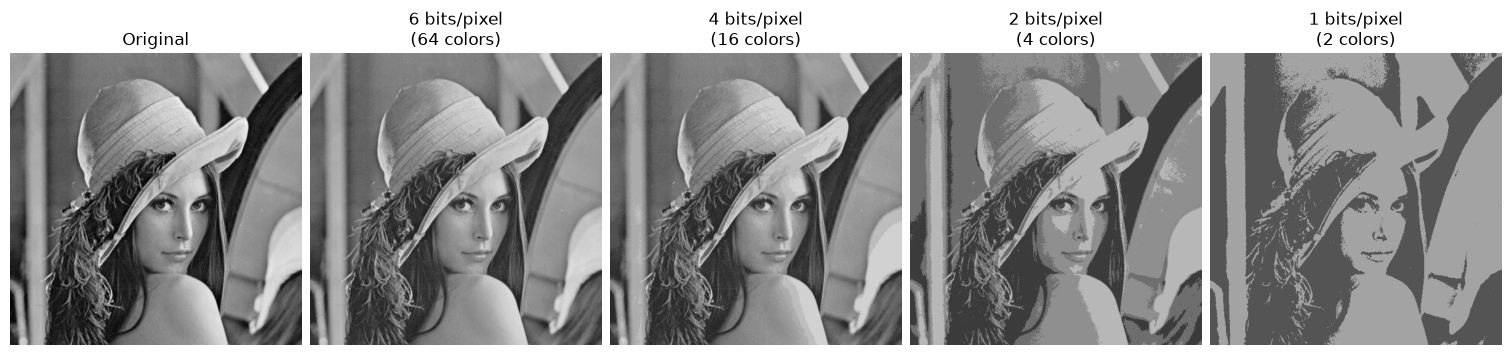

In [11]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image

# Localização do arquivo de imagem
image_1 = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena3.tif")
image_2 = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")

# Abertura do arquivo de imagem
with urlopen(image_1 ) as response:
    img_1 = Image.open(BytesIO(response.read()))
with urlopen(image_2 ) as response:
    img_2 = Image.open(BytesIO(response.read()))

# .tag_v2.get obtém detalhes da imagem como contagem de bits. 258 correponde ao código atrelado aos bits
bits_1 = img_1.tag_v2.get(258) 
bits_2 = img_2.tag_v2.get(258)

# Exibição da quantidade de bits na imagem
print(f"Image 1: size {img_1.size} and ", f"bits: {bits_1}.")
print(f"Image 2: size {img_2.size} and ", f"bits: {bits_2}. " f"For this single channel image (grayscale), the number of colors is 2^{"(num_bits)"}")

# Lista de valores de bits para o for 
bits_list = (6, 4, 2, 1)

# Organização dos plots em 1 linha por 5 colunas
fig, axes = plt.subplots(1, 5, figsize=(15, 4), constrained_layout=True)

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[1].imshow(image_R, cmap="gray")
axes[0].imshow(img_2, cmap="gray")
axes[0].set_title("Original")

# .quantize quantiza as imagem passando os bits através de color_count, pois (1 cor = 2 bits), e .MEDIANCUT para compilar a imagem novamente
for ax, bits in zip(axes[1:], bits_list):
    color_count = 2**bits
    quantized = img_2.convert("RGB").quantize(
        colors=color_count,
        method=Image.Quantize.MEDIANCUT,
    )
    ax.imshow(quantized.convert("RGB"))
    ax.set_title(f"{bits} bits/pixel\n({color_count} colors)")

for ax in axes:
    ax.axis("off")
    ax.set_box_aspect(1)

plt.show() 

COMENTÁRIO 3 - 
Lena Color tem 24 bits, 8 bits em cada canal (R,G e B) enquanto a Lena Gray tem 8 bits pois tem apenas um canal. Ao reduzir a quantidade de bits, ou seja, a quantidade de níveis de cinza e, ainda melhor, a quantidade de cores a imagem perde detalhamento e contraste. 

4) Crie uma imagem sintética cinza (resolução 256 x 256 pixels) com nível 128. Crie um quadrado
(32x32 pixels) no centro e aumente o nível de cinza desse quadrado até que ele esteja no limite da
percepção. Repita o processo, mas dessa vez diminuindo o nível de cinza do quadrado central. Você
nota alguma ilusão de óptica? Comente os resultados e explique por que a percepção humana do
brilho é uniforme no logaritmo da luminância.

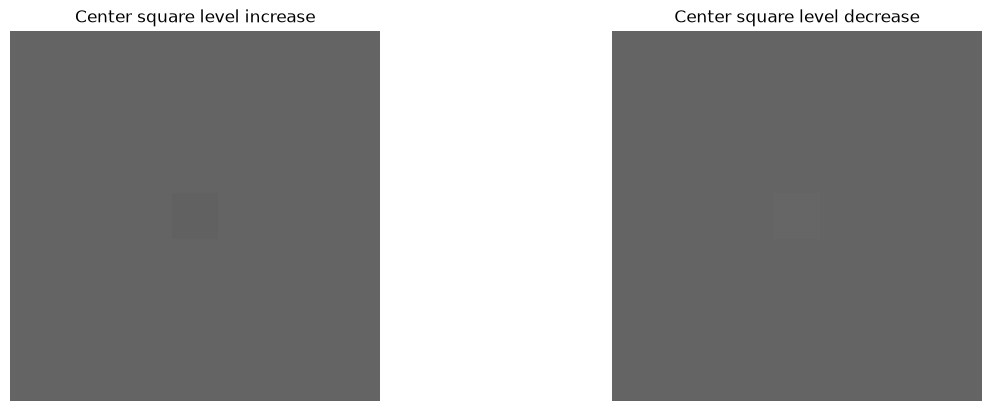

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# np.full cria uma matriz de pixel 256 x 256 com nível de cinza 50
square1 = np.full((256, 256), 50, dtype=np.uint8)  

# Seleção dos pixels dentro da matriz montando o quadrado interno e definição do valor deles para 49.9999999999999964 
square1[112:144, 112:144] = 49.9999999999999964
# np.full cria uma matriz de pixel 256 x 256 com nível de cinza 50
square2 = np.full((256, 256), 50, dtype=np.uint8)  

# Seleção dos pixels dentro da matriz montando o quadrado interno e definição do valor deles para 50.99999999999999645
square2[112:144, 112:144] = 50.99999999999999645

# Organização dos plots em 1 linha por 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

# Plots e títulos
# vmin = 0 e vmax = 128 define a escala do nível de cinza máximo
axes[0].imshow(square1, cmap="gray", vmin=0, vmax=128, interpolation="nearest")
axes[0].set_title("Center square level increase")
axes[1].imshow(square2, cmap="gray", vmin=0, vmax=128, interpolation="nearest")
axes[1].set_title("Center square level decrease")

for ax in axes:
    ax.axis("off")
plt.show()

COMENTÁRIO 4 - 
Ao reduzir ou aumentar o nível de cinza para um valor próximo do quadrado externo, o módulo da mesma diferença de nível de cinza (exemplo 50 para 49,95 e 50 para 50,05) não implica que os dois serão perceptíveis. A lei Weber-Fechner explica que, embora a luminosidade aumente linearmente, a percepção da mesma aumenta logaritmamente pois é necessário uma diferença maior que a inicial para gerar percepção da alteração. Por exemplo, sem alterar a luminosidade, ao olhar para a tela do computador de dia, o contraste é baixo, dificultando a visualização mas, ao olhar para a mesma tela de computador à noite, a visualização é muito maior.

5) Considere a imagem Frog. Aplique um ajuste de brilho a partir do escalonamento da intensidade.
Use um ajuste na escala de 1.2. Exiba as imagens lado a lado e comente os resultados.

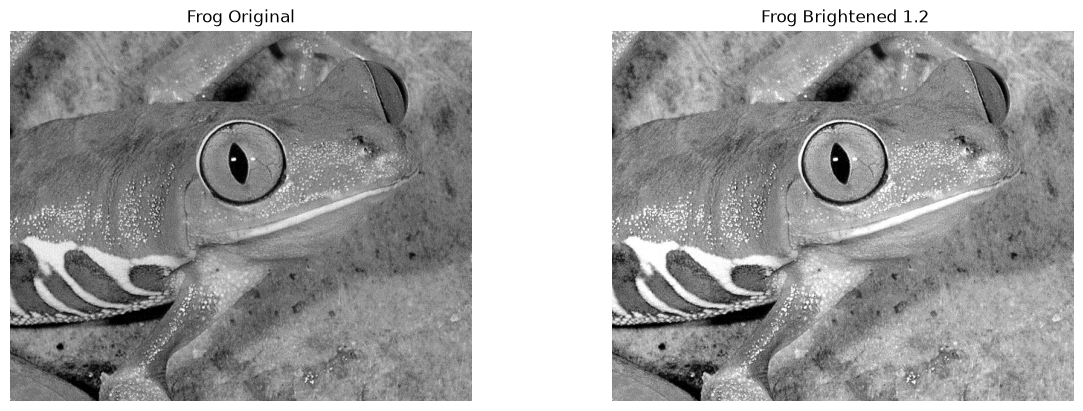

In [13]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

# Localização do arquivo de imagem
frog = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/frog.tif")

# Abertura do arquivo de imagem
with urlopen(frog) as response:
    frog = Image.open(BytesIO(response.read()))

# ImageEnhance.Brightness seleciona cada pixel e os multiplica por 1.2
image_bright = ImageEnhance.Brightness(frog).enhance(1.2)

# Organização dos plots em 1 linha por 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(frog, cmap="gray")
axes[0].set_title("Frog Original"), 

axes[1].imshow(image_bright, cmap="gray",)
axes[1].set_title(" Frog Brightened 1.2") 

for ax in axes:
    ax.axis('off')
plt.show()

COMENTÁRIO 5 -
Ao usar o escalonamento de intensidade, o nível de cinza de cada pixel é multiplicado por 1,2 igualmente. Isso acarreta em ilhas brancas, expostas demais, pois pixels entre 212 e 255 excedem 255 ao serem multiplicados por 1,2 e têm de ser corrigidos para se encaixarem na escala, gerando as regiões claras demais, sem contraste.

6) Considere a imagem Frog. Aplique um ajuste de contraste a partir da modificação do gamma.
Use gamma = 1.5. Exiba as imagens lado a lado e comente os resultados.

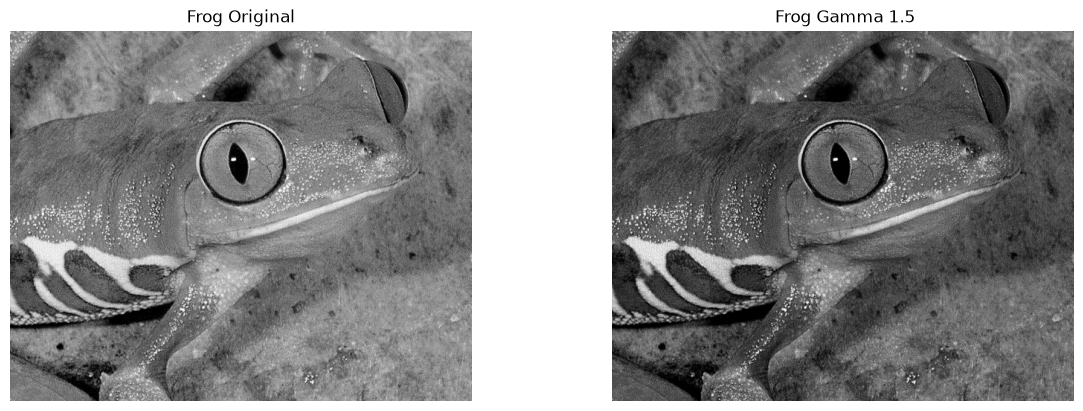

In [14]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Localização do arquivo de imagem
frog = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/frog.tif")

# Abertura do arquivo de imagem
with urlopen(frog) as response:
    frog = Image.open(BytesIO(response.read()))

# np.array transforma a imagem em um array e depois é feita a divisão das intersidades pixel a pixel entre 0 e 255
frog_array = np.array(frog, dtype=np.float32) / 255.0

# gamma_frog_array eleva cada pixel a 1/ gamma e reatribui as intensidades no nível de 0 a 255
# gamma_array trás pixels com nível menor que 0 e maior que 255 para para 0 e para 255, obedecendo a escala
#.fromarray traduz o array em imagem novamente
gamma = 1.5
gamma_frog_array = 255.0 * (frog_array **  gamma)
gamma_array = np.clip(gamma_frog_array, 0, 255).astype(np.uint8)
img_gamma_corrected = Image.fromarray(gamma_array)


# Organização dos plots em 1 linha por 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(frog, cmap="gray")
axes[0].set_title("Frog Original")

axes[1].imshow(img_gamma_corrected, cmap="gray",)
axes[1].set_title(" Frog Gamma 1.5") 

for ax in axes:
    ax.axis('off')
plt.show()

COMENTÁRIO 6 -
Ao usar a correção gamma em 1,5, níveis próximos de 0 e 255 são mantidos e trabalha-se nos tons medianos, tornando-os mais escuros gerando um contraste maior. 

7) Crie 32 imagens com ruído gaussiano a partir da imagem Brain. Aplique a técnica de supressão
de ruído a partir da média das imagens. Compare com a imagem original.

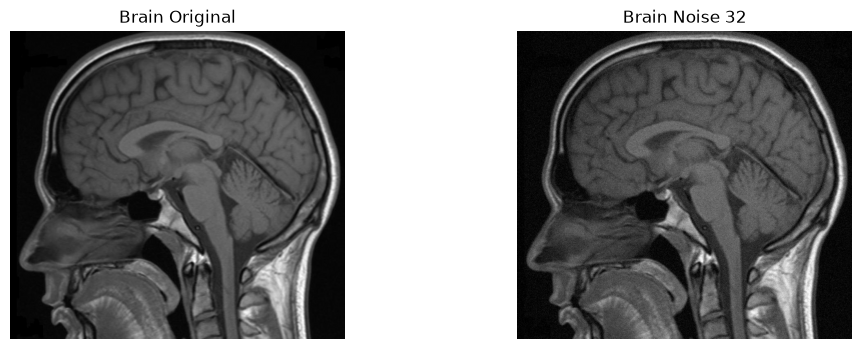

In [15]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Localização do arquivo de imagem
brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

# Abertura do arquivo de imagem
with urlopen(brain) as response:
    brain = Image.open(BytesIO(response.read()))

# np.array transforma a imagem em um array 
brain_array = np.array(brain, dtype=np.float32)

num_images = 32
mean = 0
sigma = 50 # Era 25 mas não achei visível o suficiente então dupliquei

# Variavel de lista inicialmente vazia que vai armazenar os arrays de ruído mais o brain_array
noisy_images = []

# np.random randomiza ruído normal (gaussiano) em cada uma das 32 imagens
# noisy_array_clipped trás pixels com nível menor que 0 e maior que 255 para para 0 e para 255, obedecendo a escala
# .append insere cada imagem + ruído na lista da variável noisy_images
for i in range(num_images):
    noise = np.random.normal(mean, sigma, brain_array.shape)
    noisy_array = brain_array + noise
    noisy_array_clipped = np.clip(noisy_array, 0, 255).astype(np.uint8)
    noisy_images.append(noisy_array_clipped)

# Tranformação da lista de 32 iterações de imagem + ruído em um array
noisy_stack = np.array(noisy_images)

#______________________________________________________________________________________________________________________________________________________________________________

# Deixei a seção abaixo comentada para não exibir todas as imagens com ruído. 
# Senti a necessidade de verificar se o ruído estava sendo aplicado corretamente.
# Testei com a constante de ruído sigma = 25 e não achei visível o suficiente, então dupliquei para sigma = 50.

#______________________________________________________________________________________________________________________________________________________________________________
#display_images = [Image.fromarray(noisy_stack[i]) for i in range(num_images)]

#fig, axes = plt.subplots(8, 4, figsize=(12, 24), constrained_layout=True)

#for i, ax in enumerate(axes.flat):
    #ax.imshow(display_images[i], cmap="gray")
    #ax.axis('off')
#______________________________________________________________________________________________________________________________________________________________________________

# Média do array contendo as 32 variações de imagem + ruído
median_array = np.median(noisy_stack, axis=0).astype(np.uint8)

#.fromarray traduz o array em imagem novamente
final_median_img = Image.fromarray(median_array)

# Organização dos plots em 1 linha por 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(brain, cmap="gray")
axes[0].set_title("Brain Original")

axes[1].imshow(final_median_img, cmap="gray")
axes[1].set_title("Brain Noise 32")

for ax in axes:
    ax.axis('off')
plt.show()

plt.show()

COMENTÁRIO 7 -
A imagem média apresenta cancelamento bom do ruído inseridonas 32 amostras, se aproximando da original. Ainda é perceptível ruido na imagem média pois o filtro não é perfeito mas é um grande avanço.

8) Calcule e exiba os histogramas das imagens Lena gray, Moon, Bay e Brain. Relacione o formato
dos histogramas com as características das imagens.


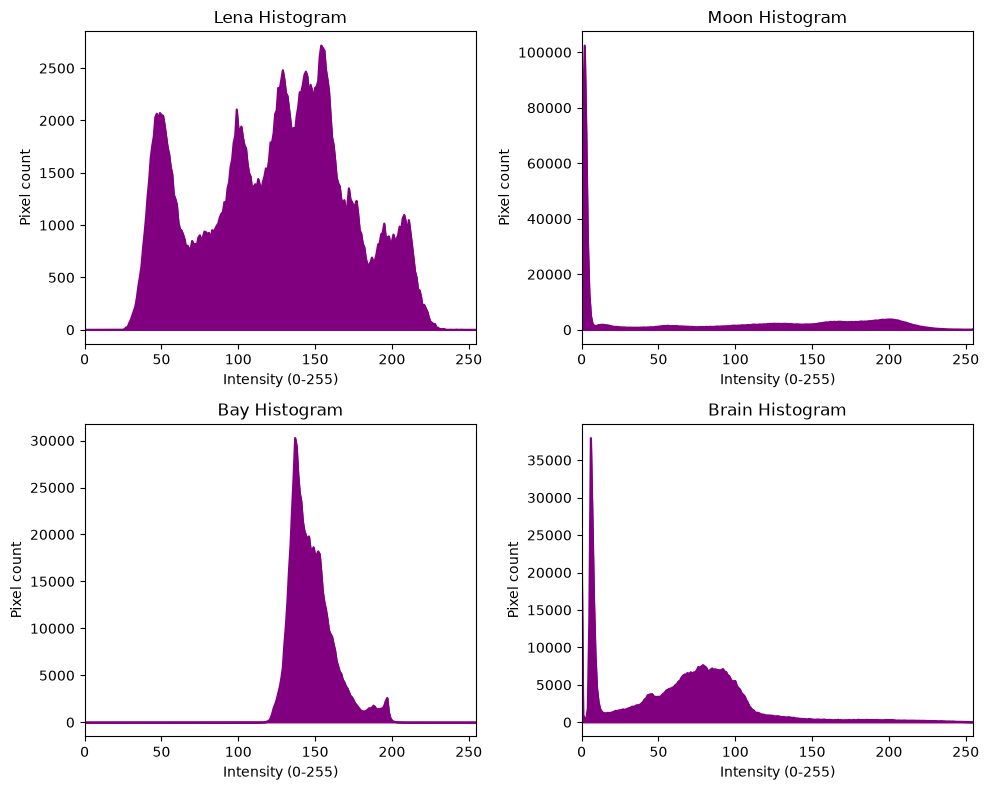

In [16]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Localização do arquivo de imagem
Lena = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")
Moon = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/moon.jpg")
Bay = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/bay.jpg")
Brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

# Abertura do arquivo de imagem
with urlopen(Lena) as response:
    lena = Image.open(BytesIO(response.read())) 
with urlopen(Moon) as response:
    moon = Image.open(BytesIO(response.read())) 
with urlopen(Bay) as response:
    bay = Image.open(BytesIO(response.read()))  
with urlopen(Brain) as response:
    brain = Image.open(BytesIO(response.read()))

# Variável tipo lista com títulos + imagens
images = {"Lena": lena,"Moon": moon,"Bay": bay,"Brain": brain,}

# Organização dos plots em 2 linha por 2 colunas
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# pixels transforma a imagem em array
# np.histogram obtém as intensidades 0 a 255 através de .ravel que produz um arranjo 1D dividido em 256 intervalos de limite 0 a 256
# np.arange trasforma em posições no gráfico (x,y) os níveis de intensidade
for ax, (name, image) in zip(axes.flat, images.items()):
    pixels = np.asarray(image)
    histogram, _ = np.histogram(pixels.ravel(), bins=256, range=(0, 256))
    intensities = np.arange(256)

# Plots e títulos
# color=purple apenas por preferência para visualização, original era azul tanto preenchimento quanto contorno
    ax.fill_between(intensities, histogram, color="purple", alpha=1.0)
    ax.plot(intensities, histogram, color="purple")
    ax.set_xlabel("Intensity (0-255)")
    ax.set_ylabel("Pixel count")
    ax.set_title(f"{name} Histogram")
    ax.set_xlim(0, 255)

plt.tight_layout()
plt.show()

COMENTÁRIO 8 -
O histograma da Lena Gray mostra uma distribuição mais normalizada com baixa amplitude dos níveis de cinza implicando que a imagem possui bom contraste.
O histograma da Moon mostra uma poplarização imensa de níveis próximos de zero e uma distribuição similar dos outros níveis monstrando que é uma imagem que possui regiões com baixíssima faixa de variação nos escuros mas contraste nos tons médios e altos.
O histograma da Bay mostra um intervalo demarcado com variação considerável de quantidade de pixels na faixa de cinza indicando um baixo contraste na faixa dos tons médios.
Por fim, o histograma de Brain mostra uma região com níves altos de pixels próximos de zero, indicando uma região muito escura, seguida de uma região mais espaçada indicando mais contraste mas ainda assim baixo.


9) Aplique a equalização de histogramas nas imagens Lena gray, Moon, Bay e Brain. Compare o
resultado com as imagens originais.


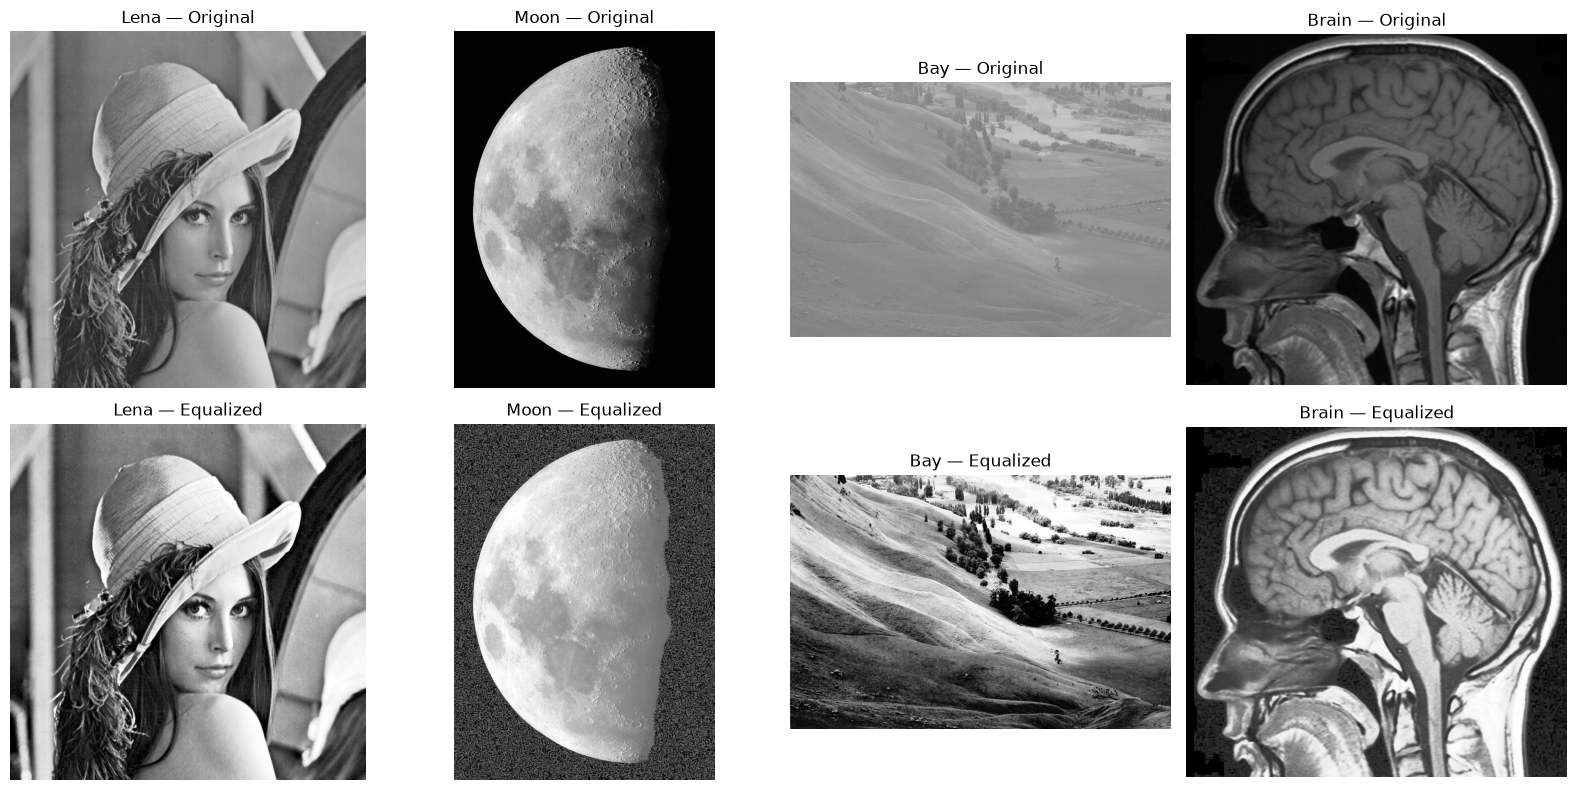

In [17]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Localização do arquivo de imagem
Lena = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")
Moon = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/moon.jpg")
Bay = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/bay.jpg")
Brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

# Abertura do arquivo de imagem
with urlopen(Lena) as response:
    lena = Image.open(BytesIO(response.read())) 
with urlopen(Moon) as response:
    moon = Image.open(BytesIO(response.read())) 
with urlopen(Bay) as response:
    bay = Image.open(BytesIO(response.read()))  
with urlopen(Brain) as response:
    brain = Image.open(BytesIO(response.read()))
    
# Variável tipo lista com títulos + imagens
images = {"Lena": lena,"Moon": moon,"Bay": bay,"Brain": brain,}

# Variáveis que armazenarão as alterações na imagem
histograms = {}
equalized_histograms = {}
equalized_images = {}

# Organização dos plots em 2 linha por 4 colunas
fig, axes = plt.subplots(2, len(images), figsize=(4 * len(images), 8), squeeze=False)

# pixels transforma a imagem em array
# np.histogram obtém as intensidades 0 a 255 através de .ravel que produz um arranjo 1D dividido em 256 intervalos de limite 0 a 256
# histogram.cumsum torna o histograma em acumulado das intensidades de pixels
# pxl_ntst_min acha o primeiro valor acumulado diferente de zero para poder espaçá-lo
# If - Se esse valor for igual ao total de pixels, imagem toda com mesma intensidade, os pixels são copiados 
# Else - Cria uma tabela de mapeamento que redistribui os níveis para 0–255

for col, (name, image) in enumerate(images.items()):
    pixels = np.asarray(image, dtype=np.uint8)
 
    histogram, _ = np.histogram(pixels.ravel(), bins=256, range=(0, 256))

    pxl_ntst = histogram.cumsum()
    pxl_ntst_min = pxl_ntst[pxl_ntst > 0][0]

    if pxl_ntst_min == pixels.size:  
        equalized_pixels = pixels.copy()
    else:
        lookup_table = np.rint((pxl_ntst - pxl_ntst_min) * 255 / (pixels.size - pxl_ntst_min)).clip(0, 255).astype(np.uint8)
        equalized_pixels = lookup_table[pixels]

    equalized_images[name] = Image.fromarray(equalized_pixels)

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
    axes[0, col].imshow(pixels, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{name} — Original")
    axes[0, col].axis("off")

    axes[1, col].imshow(equalized_images[name], cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"{name} — Equalized")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

COMENTÁRIO 9 -
Ao equalizar o histograma, imagens com níveis de cinza próximos e que inicialmente tinahm histogramas espaçados ganham mais contraste evidenciado por Lena - Equalized e mais claramente por Bay - Equalized. Entretanto, imagens com regiões regiões muito claras ou escuras, ou seja, com histogramas originais muito concentrados, apresentam granulação e clareamento ocasionando na redução de contraste.

10) Aplique a equalização adaptativa de histogramas nas imagens Lena gray, Moon, Bay e Brain.
Utilize blocos de tamanho 8x8 e 16x16 pixels. Compare os resultados com o que foi obtido na
Questão 9. 

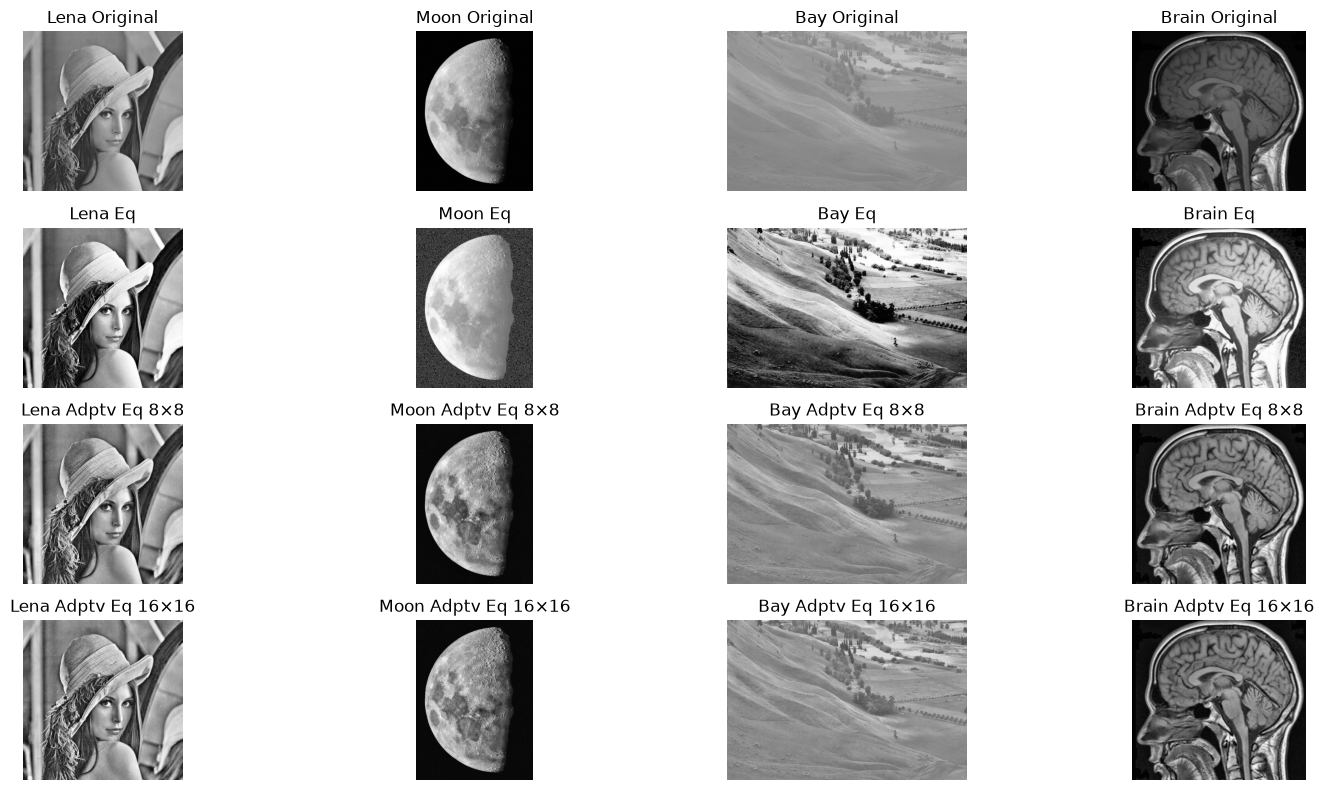

In [18]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import cv2

# Localização do arquivo de imagem
Lena = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")
Moon = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/moon.jpg")
Bay = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/bay.jpg")
Brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

# Abertura do arquivo de imagem
with urlopen(Lena) as response:
    lena = Image.open(BytesIO(response.read())) 
with urlopen(Moon) as response:
    moon = Image.open(BytesIO(response.read())) 
with urlopen(Bay) as response:
    bay = Image.open(BytesIO(response.read()))  
with urlopen(Brain) as response:
    brain = Image.open(BytesIO(response.read()))

# Variável tipo lista com títulos + imagens
images = {"Lena": lena,"Moon": moon,"Bay": bay,"Brain": brain,}

# Variáveis tipo lista que armazenarão as manipulações da imagem
histograms = {}
equalized_histograms = {}
equalized_images = {}

# Variáveis tipo lista que contém os blocos a serem equalizados
adaptive_equalized_images = {(8, 8): {},(16, 16): {},}
adaptive_equalized_histograms = {(8, 8): {},(16, 16): {},}
tile_grids = [(8, 8), (16, 16)]

# Organização dos plots em 4 linha por 4 colunas
fig, axes = plt.subplots(4, len(images), figsize=(4 * len(images), 8), squeeze=False)

# pixels transforma a imagem em array
# np.histogram obtém as intensidades 0 a 255 através de .ravel que produz um arranjo 1D dividido em 256 intervalos de limite 0 a 256
# histogram.cumsum torna o histograma em acumulado das intensidades de pixels
# pxl_ntst_min acha o primeiro valor acumulado diferente de zero para poder espaçá-lo
# If - Se esse valor for igual ao total de pixels, imagem toda com mesma intensidade, os pixels são copiados 
# Else - Cria uma tabela de mapeamento que redistribui os níveis para 0–255
for col, (name, image) in enumerate(images.items()):
    pixels = np.asarray(image, dtype=np.uint8)
 
    histogram, _ = np.histogram(pixels.ravel(), bins=256, range=(0, 256))

    pxl_ntst = histogram.cumsum()
    pxl_ntst_min = pxl_ntst[pxl_ntst > 0][0]

    if pxl_ntst_min == pixels.size:  
        equalized_pixels = pixels.copy()
    else:
        lookup_table = np.rint((pxl_ntst - pxl_ntst_min) * 255 / (pixels.size - pxl_ntst_min)).clip(0, 255).astype(np.uint8)
        equalized_pixels = lookup_table[pixels]

    equalized_images[name] = Image.fromarray(equalized_pixels)

# clahe realiza a manipulação anteiror para diversos blocos 8x8 e 16x16 da imagem original
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
    for row, tile_grid in enumerate(tile_grids, start=2):
        clahe = cv2.createCLAHE(clipLimit=2.0,tileGridSize=tile_grid,)
        adaptive_equalized_pixels = clahe.apply(pixels)

        adaptive_equalized_images[tile_grid][name] = Image.fromarray(adaptive_equalized_pixels)
        adaptive_equalized_histograms[tile_grid][name], _ = np.histogram(adaptive_equalized_pixels.ravel(), bins=256, range=(0, 256))

        axes[0, col].imshow(pixels, cmap="gray", vmin=0, vmax=255)
        axes[0, col].set_title(f"{name} Original")
        axes[0, col].axis("off")
        
        axes[1, col].imshow(equalized_pixels, cmap="gray", vmin=0, vmax=255)
        axes[1, col].set_title(f"{name} Eq")
        axes[1, col].axis("off")
        
        axes[row, col].imshow(adaptive_equalized_pixels, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{name} Adptv Eq {tile_grid[0]}×{tile_grid[1]}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

COMENTÁRIO 10 -
A equalização de histogramas para vários blocos 8x8 e 16x16, ou seja, vários mini histogramas, realça melhor detalhes e da mais amplitude para manipulação de niveis de cinza próximos de 0 e de 255. Quanto menor os blocos maior os detalhes mas também pode evidenciar ruído presente enquanto blocos maiores, ainda evicenciam detalhes mas apresentam um aspecto mais suavizado, ou seja, um pouco menos detalhado.

11) Exiba a imagem Balloons lado a lado com os seus canais R, G e B. Os canais devem ser
exibidos como imagens monocromáticas. Explique.


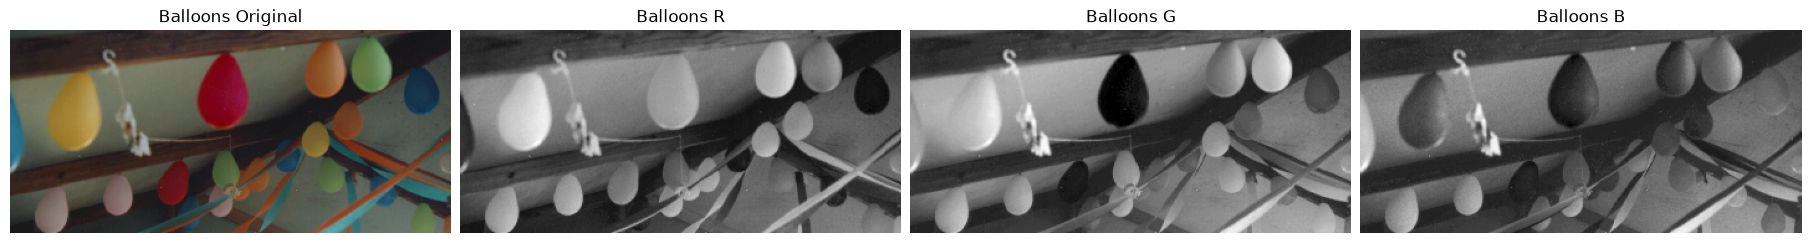

In [19]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image

# Localização do arquivo de imagem
balloons = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/balloons.tif")

# Abertura do arquivo de imagem
with urlopen(balloons) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

# Obtenção dos canais individuais
R = original.getchannel("R")
G = original.getchannel("G")    
B = original.getchannel("B")

# Organização dos plots em 1 linha por 4 colunas
fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(original)
axes[0].set_title(f"Balloons Original")
axes[1].imshow(R, cmap= "gray")
axes[1].set_title(f"Balloons R")
axes[2].imshow(G, cmap= "gray")
axes[2].set_title(f"Balloons G")
axes[3].imshow(B, cmap= "gray")
axes[3].set_title(f"Balloons B")

for ax in axes:
    ax.axis("off")

COMENTÁRIO 11 - 
Na imagem do canal R, os balões com níveis de vermelho (vermelho, rosa claro, laranja, amarelo, e verde) são exibidos em níveis de cinza médios claros enquanto os azuis são exibidos em níveis de cinza próximos a zero (preto) pois o azul possui pouco ou quase nenhum vermelho em sua composição.
Na imagem do canal G, os balões com níveis de verde (rosa claro, laranja, amarelo, verde e azul) são exibidos em níveis de cinza médios claros enquanto os vermelhos são exibidos em níveis de cinza próximos a zero (preto) pois o para este comprimento de onda de vermelho (cor vermelha forte bem definida) há pouca presença de níveis de verde. Caso houvese mais presença de verde, o balão seria alaranjado.
Na imagem do canal B, todas as cores possuem variadas interseções com o azul pois o azul possui comprimentos de onda dentro do verde e do vermelho.

12) Converta a imagem Balloons para níveis de cinza a partir da média dos canais. Em seguida
converta utilizando a função de conversão padrão. Exiba as imagens lado a lado e explique por que
elas são diferentes.

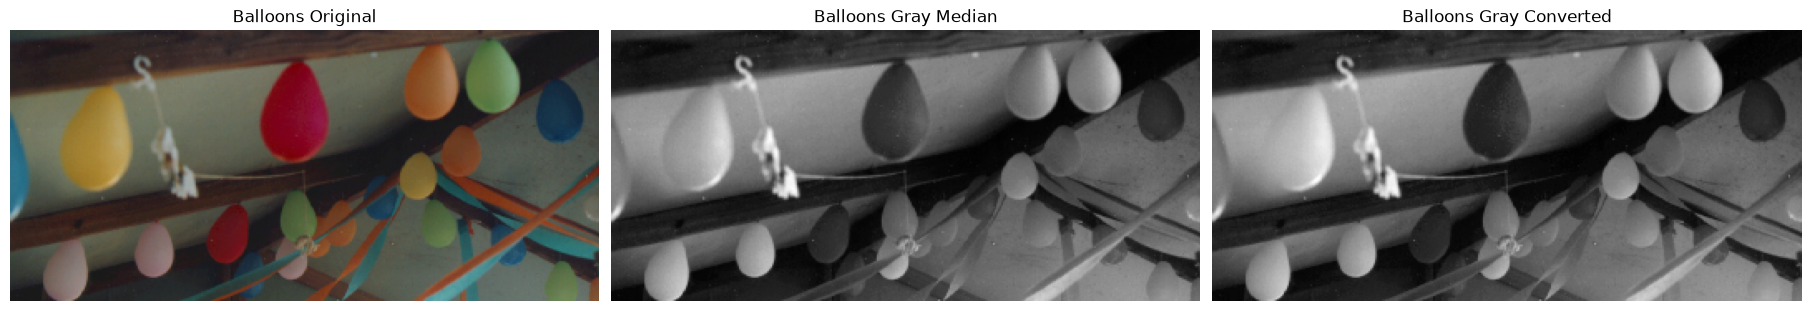

In [20]:
from io import BytesIO
from urllib.request import urlopen
from PIL import Image
import numpy as np

# Localização do arquivo de imagem
image_url = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/balloons.tif")

# Abertura do arquivo de imagem
with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

# Conversão de original para níveis de cinza
original_gray = original.convert("L")

# Obtenção dos canais individuais
R = original.getchannel("R")
G = original.getchannel("G")    
B = original.getchannel("B")

# Transformação das imagens dos canais em arrays
R_array = np.array(R, dtype=np.float32)
G_array = np.array(G, dtype=np.float32)
B_array = np.array(B, dtype=np.float32)

# Média dos canais corrigidos para escala 0 a 255
gray_mean = np.clip((R_array + G_array + B_array) / 3.0, 0, 255).astype(np.uint8)
gray_img = Image.fromarray(gray_mean)

# Organização dos plots em 1 linha por 4 colunas
fig, axes = plt.subplots(1, 3, figsize=(18, 4), constrained_layout=True)

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(original)
axes[0].set_title(f"Balloons Original")
axes[1].imshow(gray_img, cmap= "gray")
axes[1].set_title(f"Balloons Gray Median",)
axes[2].imshow(original_gray, cmap="gray")
axes[2].set_title(f"Balloons Gray Converted")

for ax in axes:
    ax.axis("off")

COMENTÁRIO 12 - 
Ao aplicar a média nos canais RGB, todos canais são tradados como iguais, possuem os mesmos pesos, não há correção por constantes para adequar a exibição. Enquanto na conversão padrão do Pillow, os pesos para cada cor são predefinidos, efetuando a correção para exibição otimizada.

13) Converta a imagem Peppers_color para níveis de cinza. Aplique uma binarização por limiar
global para destacar apenas a cor vermelha. Em seguida, use a imagem binária como máscara e
aplique na imagem original. Explique por que a segmentação contém algumas imperfeições
indesejadas.

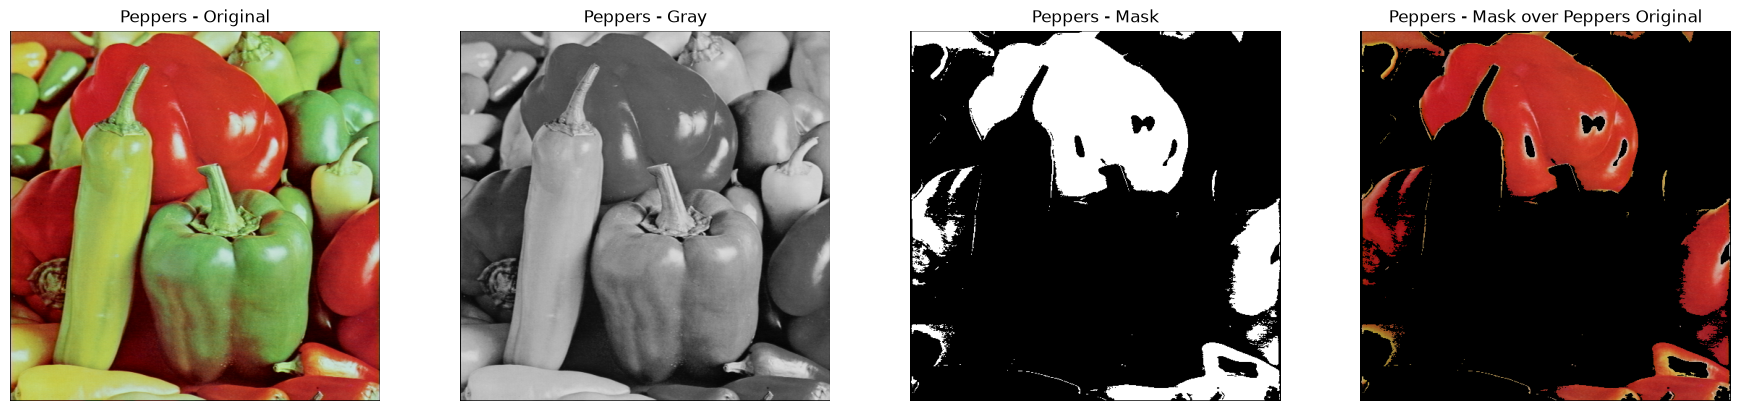

In [21]:
from io import BytesIO
from urllib.request import urlopen
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Localização do arquivo de imagem
image_url = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/peppers3.tif")

# Abertura do arquivo de imagem
with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

image_array = np.array(original)

# Conversão de original para níveis de cinza
original_gray = original.convert("L")

# Obtenção dos canais individuais
R = image_array[:, :, 0]
G = image_array[:, :, 1]
B = image_array[:, :, 2]

# Binarização por limiar global para destacar vermelho
# Pixel vermelho tem R alto e G e B mais baixos
threshold = 150
mask = (R > threshold) & (R > G + 20) & (R > B + 20)

# Aplica a máscara na imagem original
result = np.copy(image_array)
result[~mask] = 0

# Organização dos plots em 1 linha por 4 colunas
fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(original)
axes[0].set_title(f"Peppers - Original")
axes[1].imshow(original_gray, cmap= "gray")
axes[1].set_title(f"Peppers - Gray",)
axes[2].imshow(mask, cmap="gray")
axes[2].set_title(f"Peppers - Mask")
axes[3].imshow(result, cmap="gray")
axes[3].set_title(f"Peppers - Mask over Peppers Original")

for ax in axes:
    ax.axis("off")

COMENTÁRIO 13 - 

As imperfeições ocorrem pois ao utilizar o limiar global, valores muito extremos estão sendo comparados acarretando em detalhes finos, como tons de vermelho mais escuros ou claros, sendo desprezados como podemos notar na Peppers - Original, nos buracos dos pimentões e nas pontas mais escurecidas onde seriam mais sombreados. Além disso, imperfeições nas bordas, descontinuidades, são apresentadas pois são pixels de transição então possuem níveis de verde e azul. 

14) Converta a imagem Guia para níveis de cinza e em seguida aplique o Otsu global. Em seguida,
aplique a binarização localmente adaptativa. Use a variância como medida de uniformidade. Qual é
o tamanho de janela que acarreta em melhor resultado?

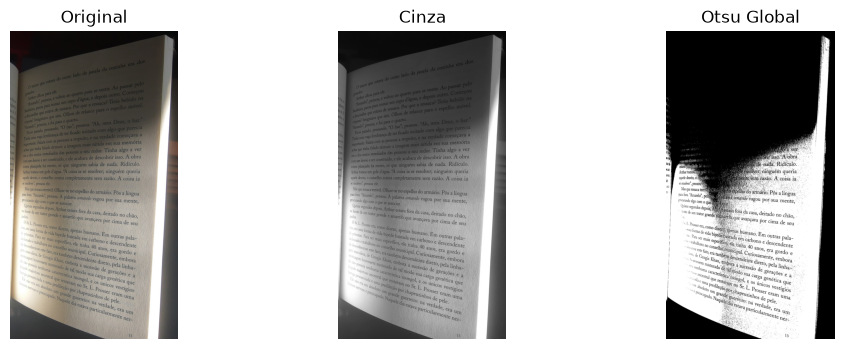

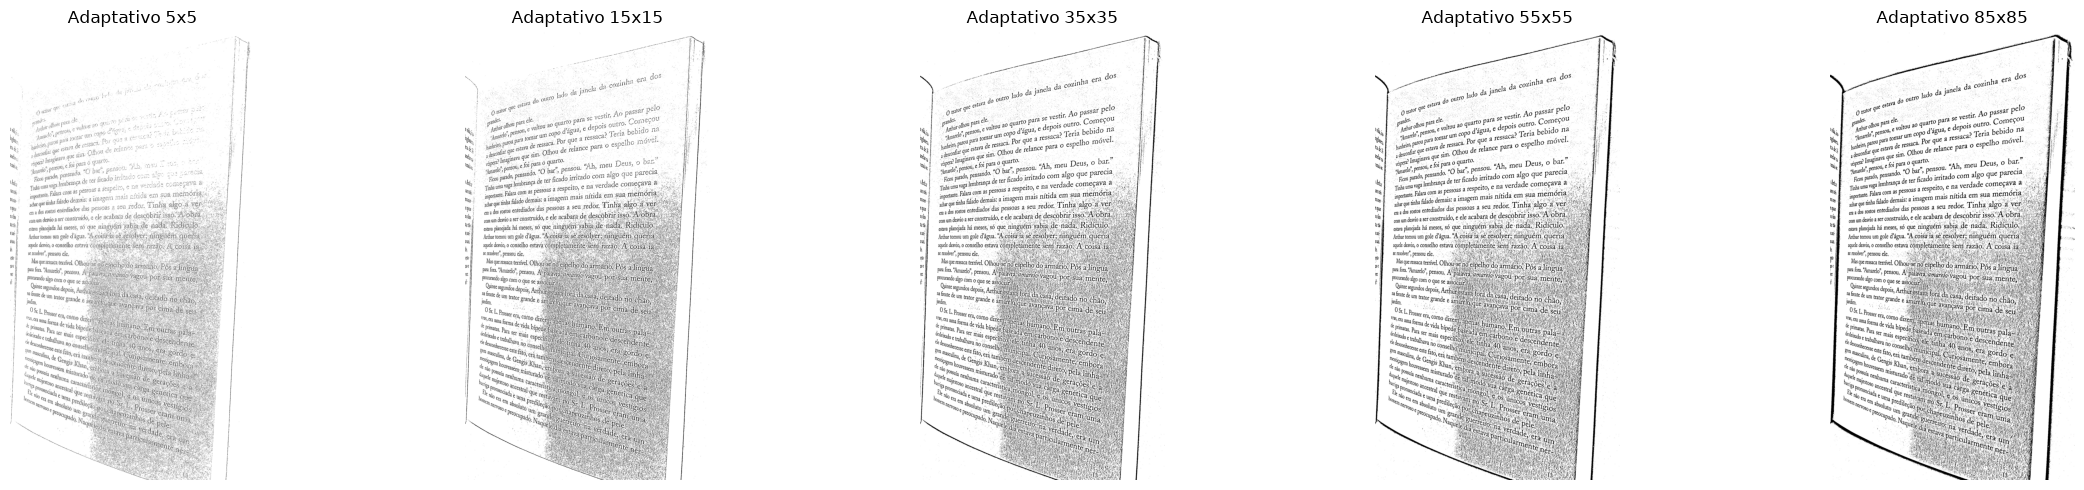

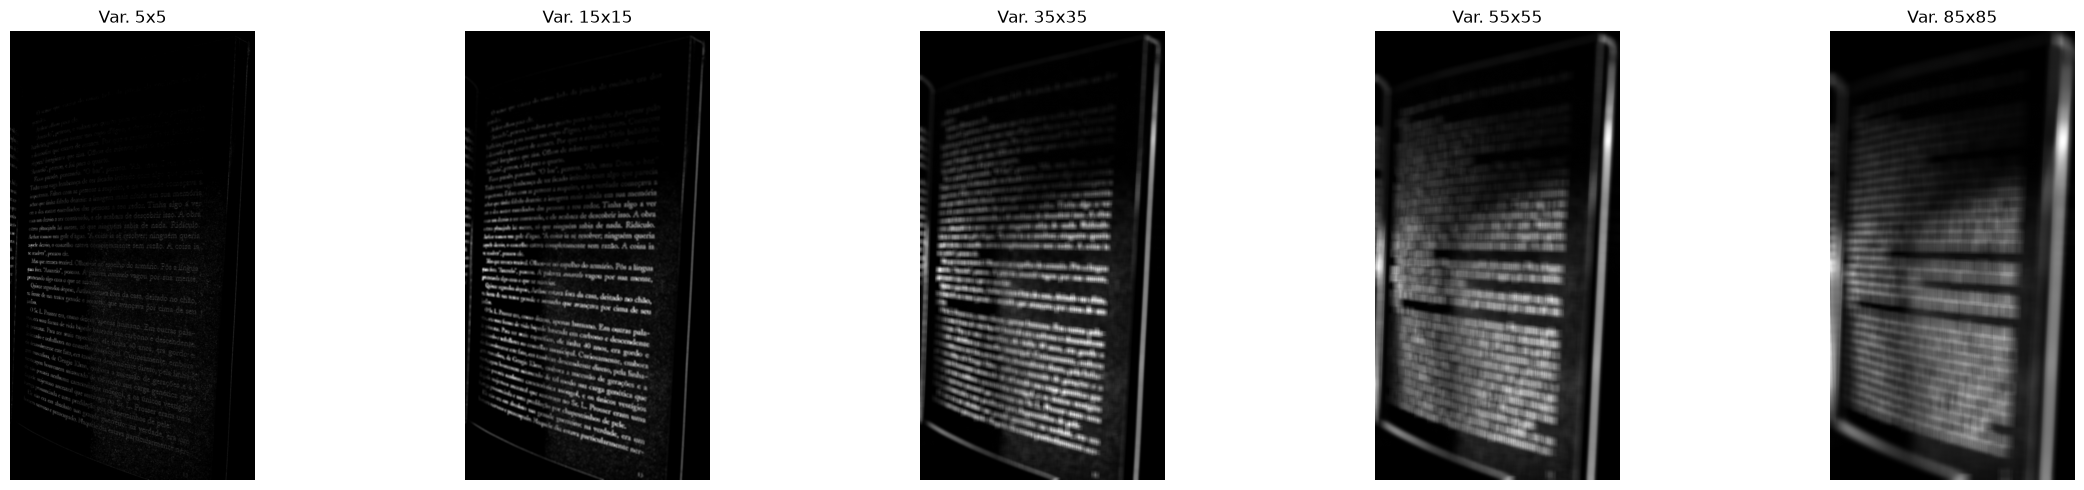

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO
from urllib.request import urlopen
from PIL import Image

# Localização do arquivo de imagem
image_url = "https://raw.githubusercontent.com/florencio300/LISTA-1-PROC-SIN-II/main/dataset/guia.jpg"

# Abertura do arquivo de imagem
with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")
    original_array = np.array(original)

# Conversão para níveis de cinza
gray = cv2.cvtColor(original_array, cv2.COLOR_RGB2GRAY)

# Limiar global por Otsu
th_otsu, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Variância local para cada janela
window_sizes = [5, 15, 35, 55, 85]
var_results = []

for ws in window_sizes:
    if ws % 2 == 0:
        ws += 1
    local_mean = cv2.blur(gray.astype(np.float32), (ws, ws))
    local_var = cv2.blur((gray.astype(np.float32) - local_mean)**2, (ws, ws))
    var_results.append((ws, local_var))

# Limiar adaptativo local
adaptive_results = []

for ws in window_sizes:
    if ws % 2 == 0:
        ws += 1
    adaptive = cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,ws,10)
    adaptive_results.append((ws, adaptive))

# Organização dos plots em 1 linha por 3 colunas
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(original)
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Cinza")
axes[1].axis("off")
axes[2].imshow(otsu, cmap="gray")
axes[2].set_title(f"Otsu Global")
axes[2].axis("off")

# Organização dos plots em 1 linha por 5 colunas
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
for i, (ws, img) in enumerate(adaptive_results):
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Adaptativo {ws}x{ws}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Organização dos plots de variância em 1 linha por 5 colunas
fig, axes = plt.subplots(1, len(var_results), figsize=(24, 5))

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, matplotlib automaticamente aplica um esquema de cores em tons de verde e azul
for i, (ws, img_var) in enumerate(var_results):
    axes[i].imshow(img_var, cmap="gray")
    axes[i].set_title(f"Var. {ws}x{ws}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

COMENTÁRIO 14 -
Usando a variância como medida de uniformidade, a janela que oferece melhor resultado entre obter os detalhes de alta variância como o texto e bordas, e detalhes de baixa variância como o fundo da página e fora do livro é a janela 35x35. As janelas 15x15 e 35x35 são as mais produtivas na variância pois oferecem melhor qualidade de detalhes como texto, bordas e fundo. A 15x15 perde poucas bordas enquanto a 35x35 as mantém, abrindo mão da definição do texto. 